# Principal component analysis

Standardize and encode mixed-type features, then inspect PCA variance and a reduced-feature classifier.

**Dataset:** `data/student_data.csv` (395 student records, 33 columns). **Target:** final grade `G3` (0–20). For classification labs, pass means `G3 ≥ 10`. Earlier grades `G1` and `G2` are included as predictors; interpret results as prediction after those earlier grades are known. The split is fixed with random seed 42 for reproducibility.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATHS = [Path("data/student_data.csv"), Path("../data/student_data.csv")]
DATA_PATH = next((p for p in DATA_PATHS if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place student_data.csv in the repository's data/ folder.")
df = pd.read_csv(DATA_PATH)
TARGET = "G3"  # final-period grade (0–20)
PASS_THRESHOLD = 10
numeric_features = df.select_dtypes(include=np.number).columns.drop(TARGET).tolist()
categorical_features = df.select_dtypes(exclude=np.number).columns.tolist()
feature_cols = numeric_features + categorical_features
X = df[feature_cols]
y_reg = df[TARGET]
y_class = (df[TARGET] >= PASS_THRESHOLD).astype(int)


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

def make_preprocessor(scale_numeric=True):
    numeric_steps = [("scale", StandardScaler())] if scale_numeric else []
    numeric_pipe = Pipeline(numeric_steps) if numeric_steps else "passthrough"
    return ColumnTransformer(
        [("numeric", numeric_pipe, numeric_features),
         ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)],
        remainder="drop",
    )


Encoded dimensions: 58 | retained components: 30
Cumulative explained variance: 0.958


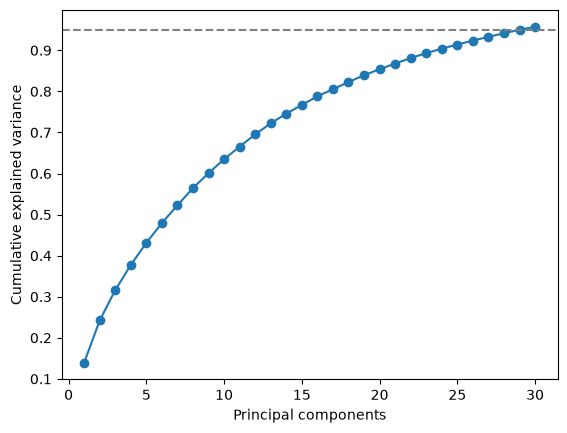

PCA + logistic accuracy: 0.838 | macro F1: 0.829


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

X_train,X_test,y_train,y_test=train_test_split(X,y_class,test_size=0.25,stratify=y_class,random_state=42)
prep=make_preprocessor(); A=prep.fit_transform(X_train); B=prep.transform(X_test)
# The mixed numeric/categorical transformer can return a sparse matrix; PCA needs dense input here.
if hasattr(A, "toarray"):
    A, B = A.toarray(), B.toarray()
pca=PCA(n_components=0.95,svd_solver="full",random_state=42)
A_pca=pca.fit_transform(A); B_pca=pca.transform(B)
print("Encoded dimensions:",A.shape[1],"| retained components:",pca.n_components_)
print("Cumulative explained variance:",round(pca.explained_variance_ratio_.sum(),3))
plt.plot(np.arange(1,len(pca.explained_variance_ratio_)+1),np.cumsum(pca.explained_variance_ratio_),marker="o")
plt.axhline(.95,color="gray",linestyle="--"); plt.xlabel("Principal components"); plt.ylabel("Cumulative explained variance"); plt.show()
clf=LogisticRegression(max_iter=2000,class_weight="balanced").fit(A_pca,y_train)
pred=clf.predict(B_pca)
print("PCA + logistic accuracy:",round(accuracy_score(y_test,pred),3),"| macro F1:",round(f1_score(y_test,pred,average="macro"),3))
